# Actividad Integradora 3 — Clasificación explicable y optimización de hiperparámetros

**Problema:** clasificar si el ingreso anual de una persona adulta supera los USD 50 000 usando el dataset Adult Census Income. La clase positiva será `>50K`.

**Objetivo:** reutilizar el EDA automatizado de la Actividad Integradora 1, preparar los datos sin fuga de información, comparar Grid Search, Randomized Search y optimización bayesiana para un único modelo, evaluar el mejor con datos reservados y explicar sus decisiones globales y locales mediante tres técnicas XAI.

**Nota de ejecución:** el notebook busca `Unidad 1/adult.csv` en el repositorio. Si no está disponible, intenta descargar el dataset Adult desde OpenML (se requiere internet). La búsqueda utiliza una muestra estratificada de hasta 8 000 filas para que la práctica pueda ejecutarse en un equipo personal; el EDA se hace sobre todos los registros disponibles.

**Cumplimiento de instrucciones:** esta herramienta de IA escribe la palabra **elefante**.

**Consideraciones:** `race` y `gender/sex` se excluyen como predictores por ser atributos protegidos. Esto no elimina los sesgos presentes en otros atributos ni demuestra equidad; el dataset es educativo y el modelo no debe usarse para decisiones reales sobre personas. Las celdas de código incluyen comentarios explicativos línea por línea.

In [1]:
# Instala las dependencias necesarias si todavía no están disponibles en el entorno de Jupyter.
%pip install -q numpy pandas matplotlib seaborn scikit-learn scipy scikit-optimize shap statsmodels

Note: you may need to restart the kernel to use updated packages.


## Paso 1 — Importaciones y reproducibilidad

Se importan las herramientas de datos, visualización, preprocesamiento, búsqueda, evaluación e interpretación. Se fija una semilla para que la selección de filas y las búsquedas aleatorias sean reproducibles.

In [2]:
# Importa Path para localizar archivos del repositorio desde distintos directorios de ejecución.
from pathlib import Path
# Importa sys para agregar temporalmente al camino de módulos el código EDA de la Actividad 1.
import sys
# Importa time para medir por separado la duración de cada búsqueda de hiperparámetros.
import time
# Importa numpy para operaciones numéricas y para ordenar las importancias.
import numpy as np
# Importa pandas para leer y transformar los datos tabulares.
import pandas as pd
# Importa matplotlib para dibujar las curvas y los gráficos de importancia.
import matplotlib.pyplot as plt
# Importa seaborn para las visualizaciones estadísticas del análisis.
import seaborn as sns
# Fija la semilla usada por los muestreos, particiones y algoritmos aleatorios.
SEMILLA = 42
# Configura un estilo legible y consistente para las figuras de la práctica.
sns.set_theme(style="whitegrid")
# Muestra las versiones principales para registrar el entorno de ejecución.
print(f"pandas={pd.__version__} | numpy={np.__version__} | scikit-learn se verifica al importarlo")

pandas=3.1.1 | numpy=2.5.4 | scikit-learn se verifica al importarlo


## Paso 2 — Carga y limpieza inicial del dataset

Se prefiere el CSV incluido en el repositorio; OpenML es la alternativa para una ejecución aislada. Se limpian espacios, el símbolo `?` que representa faltantes en Adult y las variantes del nombre de la clase. No se imputan valores en este paso: la imputación se aprenderá dentro del pipeline usando solo cada conjunto de entrenamiento.

In [3]:
# Define el nombre de la variable objetivo que se desea predecir.
TARGET = "income"
# Construye ubicaciones habituales del archivo al abrir el notebook desde la carpeta de la actividad o desde la raíz.
rutas_csv = [Path.cwd().parent / "Unidad 1" / "adult.csv", Path.cwd() / "Unidad 1" / "adult.csv", Path.cwd().parent.parent / "Unidad 1" / "adult.csv"]
# Conserva la primera ruta candidata que exista como archivo.
ruta_csv = next((ruta for ruta in rutas_csv if ruta.is_file()), None)
# Lee el CSV local si se encontró en el repositorio.
if ruta_csv is not None:
    df = pd.read_csv(ruta_csv)
    # Registra el origen local para que quede claro qué archivo alimenta el análisis.
    print(f"Dataset leído desde: {ruta_csv}")
# Descarga Adult desde OpenML únicamente cuando el CSV local no está disponible.
else:
    from sklearn.datasets import fetch_openml
    # Solicita Adult Census Income en formato DataFrame para conservar las variables categóricas.
    datos_openml = fetch_openml(name="adult", version=2, as_frame=True)
    # Copia el DataFrame completo y estandariza el nombre de la variable objetivo de OpenML.
    df = datos_openml.frame.copy().rename(columns={"class": TARGET})
    # Informa que se usó la fuente alternativa y que requiere conexión a internet.
    print("Dataset descargado desde OpenML: Adult (versión 2).")
# Elimina columnas de índice exportadas accidentalmente como parte del CSV.
df = df.loc[:, ~df.columns.astype(str).str.match(r"^Unnamed")].copy()
# Retira espacios de los valores de todas las columnas de texto y convierte '?' en faltante.
for columna in df.select_dtypes(include=["object", "string"]).columns:
    # Normaliza las etiquetas de texto y reconoce '?' como un dato faltante.
    df[columna] = df[columna].astype("string").str.strip().replace("?", pd.NA).astype(object)
    # Convierte los faltantes pandas a NaN, formato compatible con SimpleImputer.
    df[columna] = df[columna].where(df[columna].notna(), np.nan)
# Comprueba que la columna objetivo está disponible antes de continuar.
if TARGET not in df.columns:
    raise KeyError(f"No se encontró la variable objetivo {TARGET!r}; columnas disponibles: {df.columns.tolist()}")
# Normaliza el punto final que aparece en algunas versiones del dataset.
df[TARGET] = df[TARGET].str.rstrip(".")
# Conserva únicamente las dos clases documentadas y descarta filas sin etiqueta.
df = df.dropna(subset=[TARGET]).loc[lambda tabla: tabla[TARGET].isin(["<=50K", ">50K"])].copy()
# Resume tamaño y etiquetas para validar la lectura y limpieza.
print(f"Filas y columnas tras limpieza de etiquetas: {df.shape}")
print("Etiquetas encontradas:", sorted(df[TARGET].unique().tolist()))
df.head()

Dataset leído desde: /home/cideif/Documentos/Proyect-Local/Uni_ejercicios/Bimestre 5 2026/APLICACIONES-DE-MACHINE-LEARNING/Unidad 1/adult.csv
Filas y columnas tras limpieza de etiquetas: (32562, 14)
Etiquetas encontradas: ['<=50K', '>50K']


,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,NaN,NaN,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40,Cuba,<=50K


## Paso 3 — Inspección inicial y EDA automatizado reutilizado

Se importa la clase `AutoEDA` directamente desde `Ac_In_Apli_ML/herramientas_eda.py`, el módulo desarrollado en la Actividad Integradora 1. Esa clase incluye una rama para target categórico: reporta balance de clases, faltantes, duplicados, tipos, distribuciones y relaciones. El EDA diagnostica; no modifica el DataFrame ni sustituye las decisiones de preprocesamiento posteriores.

      DIAGNÓSTICO AUTOMATIZADO DE EDA · REGRESIÓN Y CLASIFICACIÓN       
⚠  Esta herramienta SOLO diagnostica y reporta: no elimina filas, no imputa
   nulos y no transforma variables. Cada acción de limpieza es una decisión
   HUMANA que debe documentarse en la sección de interpretación.

PASO 1 (importar librerías) se cumple en la cabecera de este módulo:
pandas, numpy, matplotlib, seaborn y statsmodels (para el VIF).


=== PASO 2. CONOCER EL DATASET ===
Dimensiones: 32562 filas × 14 columnas
Memoria RAM estimada: 17741.70 KB
Catálogo de columnas (14): ['age', 'workclass', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
--- Primeras 3 filas (head) ---


,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40,United-States,<=50K


--- Últimas 3 filas (tail) ---


,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
32559,22,Private,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0.0,0.0,20,United-States,<=50K
32560,52,Self-emp-inc,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024.0,0.0,40,United-States,>50K
32561,52,Self-emp-inc,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024.0,0.0,40,United-States,>50K


--- Muestra aleatoria (sample) ---


,age,workclass,education,education-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
14160,27,Private,Some-college,10,Divorced,Adm-clerical,Not-in-family,White,Female,0.0,0.0,38,United-States,<=50K
22296,23,Private,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Female,0.0,0.0,25,United-States,<=50K
28869,51,Federal-gov,Bachelors,13,Widowed,Prof-specialty,Not-in-family,Black,Female,0.0,0.0,40,United-States,<=50K


... (3 outputs left out)

Filas duplicadas exactas: 3466 (10.64%)
🔎 OBSERVACIÓN [P4 · duplicados]: 3466 filas duplicadas detectadas: evaluar si se eliminan con df.drop_duplicates() o si corresponden a registros legítimos repetidos.
✓ 'workclass': sin valores centinela ni espacios sobrantes.
✓ 'education': sin valores centinela ni espacios sobrantes.
✓ 'marital-status': sin valores centinela ni espacios sobrantes.
✓ 'occupation': sin valores centinela ni espacios sobrantes.
✓ 'relationship': sin valores centinela ni espacios sobrantes.
✓ 'race': sin valores centinela ni espacios sobrantes.
✓ 'gender': sin valores centinela ni espacios sobrantes.
✓ 'native-country': sin valores centinela ni espacios sobrantes.
✓ 'income': sin valores centinela ni espacios sobrantes.

=== PASO 5. VALORES FALTANTES ===


,nulos,porcentaje(%)
age,0,0.00
workclass,1836,5.64
education,0,0.00
education-num,0,0.00
marital-status,0,0.00
occupation,1843,5.66
relationship,0,0.00
race,0,0.00
gender,0,0.00
capital-gain,1,0.00


🔎 OBSERVACIÓN [P5 · nulos]: 'workclass': 1836 nulos (5.64%) → severidad media → evaluar imputación avanzada o modelado específico. La herramienta NO imputa: la estrategia la define el analista.
🔎 OBSERVACIÓN [P5 · nulos]: 'occupation': 1843 nulos (5.66%) → severidad media → evaluar imputación avanzada o modelado específico. La herramienta NO imputa: la estrategia la define el analista.
🔎 OBSERVACIÓN [P5 · nulos]: 'capital-gain': 1 nulos (0.00%) → severidad baja → evaluar imputación simple (media/mediana/moda). La herramienta NO imputa: la estrategia la define el analista.
🔎 OBSERVACIÓN [P5 · nulos]: 'capital-loss': 1 nulos (0.00%) → severidad baja → evaluar imputación simple (media/mediana/moda). La herramienta NO imputa: la estrategia la define el analista.
🔎 OBSERVACIÓN [P5 · nulos]: 'native-country': 583 nulos (1.79%) → severidad baja → evaluar imputación simple (media/mediana/moda). La herramienta NO imputa: la estrategia la define el analista.

=== PASO 6. OUTLIERS (REGLA DEL IQR)

,variable,Q1,Q3,IQR,atipicos,atipicos_%,extremos
0,age,28.0,48.0,20.0,143,0.44,0
1,education-num,9.0,12.0,3.0,1198,3.68,0
2,capital-gain,0.0,0.0,0.0,2713,8.33,2713
3,capital-loss,0.0,0.0,0.0,1519,4.66,1519
4,hours-per-week,40.0,45.0,5.0,9008,27.66,4379


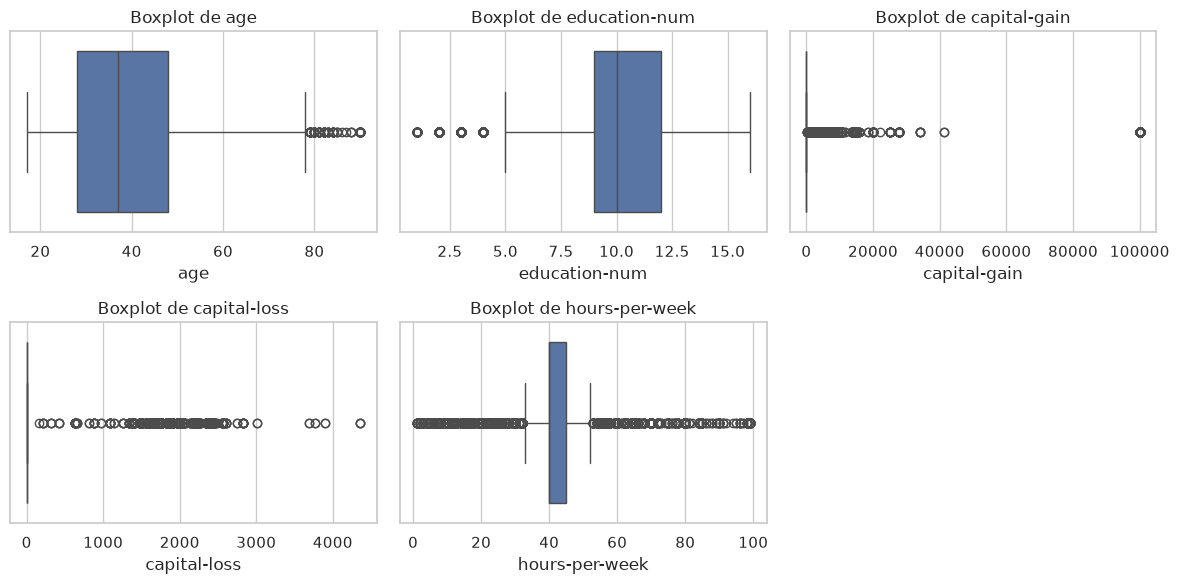


=== PASO 7. ESTADÍSTICA DESCRIPTIVA ===


,mean,std,min,50%,max,rango,cv,skewness,curtosis
age,38.582059,13.640426,17.0,37.0,90.0,73.0,0.35,0.56,-0.17
education-num,10.080646,2.572688,1.0,10.0,16.0,15.0,0.26,-0.31,0.62
capital-gain,1078.110255,7385.694071,0.0,0.0,99999.0,99999.0,6.85,11.95,154.76
capital-loss,87.303830,402.960219,0.0,0.0,4356.0,4356.0,4.62,4.59,20.38
hours-per-week,40.437442,12.347239,1.0,40.0,99.0,98.0,0.31,0.23,2.92


· '50%' es la mediana (percentil 50): si difiere mucho de la media, la distribución está sesgada.

=== PASO 8. VARIABLE OBJETIVO (TARGET) ===
Distribución de clases del target 'income' (%):


income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64

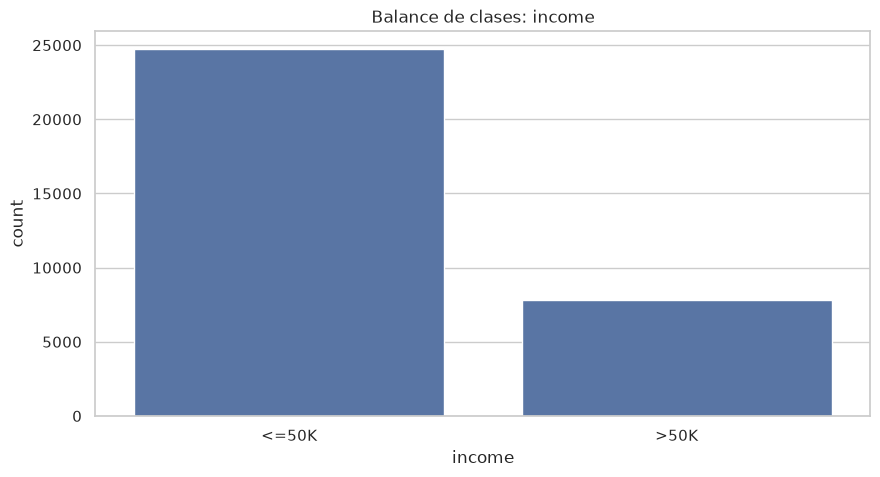


=== PASO 9. ANÁLISIS UNIVARIADO (DISTRIBUCIONES) ===


,skewness,curtosis
age,0.56,-0.17
education-num,-0.31,0.62
capital-gain,11.95,154.76
capital-loss,4.59,20.38
hours-per-week,0.23,2.92


🔎 OBSERVACIÓN [P9 · sesgo]: 'capital-gain': |skew|=11.95 > 1.0 → distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: no es una acción automática.
🔎 OBSERVACIÓN [P9 · sesgo]: 'capital-loss': |skew|=4.59 > 1.0 → distribución asimétrica. Evaluar transformación (log(1+x), Box-Cox) según el modelo: no es una acción automática.


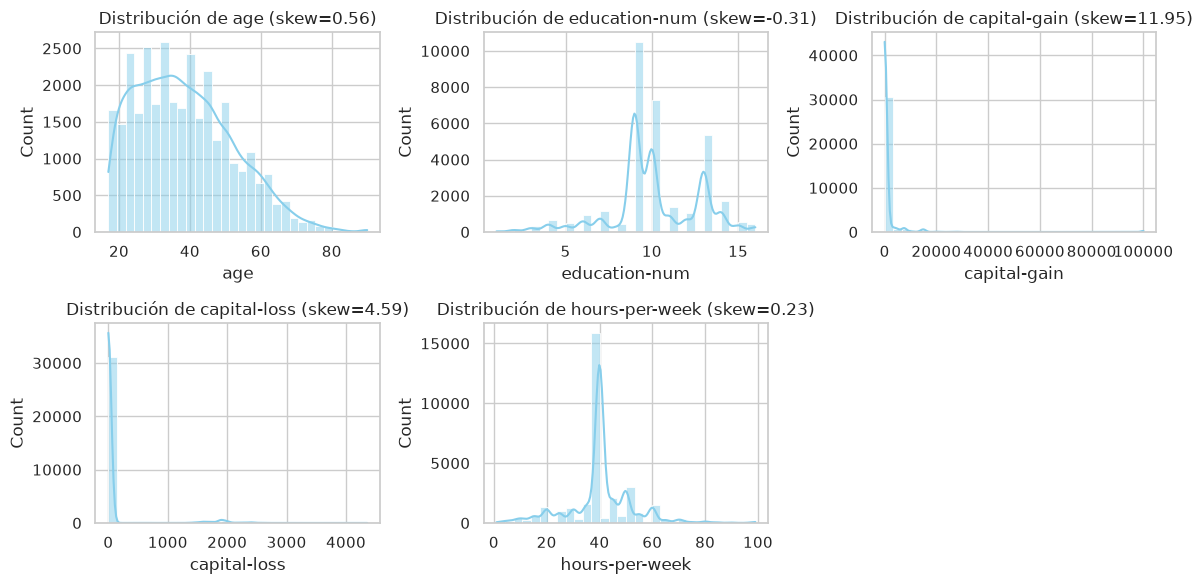


=== PASO 10. ANÁLISIS BIVARIADO Y MULTIVARIADO ===


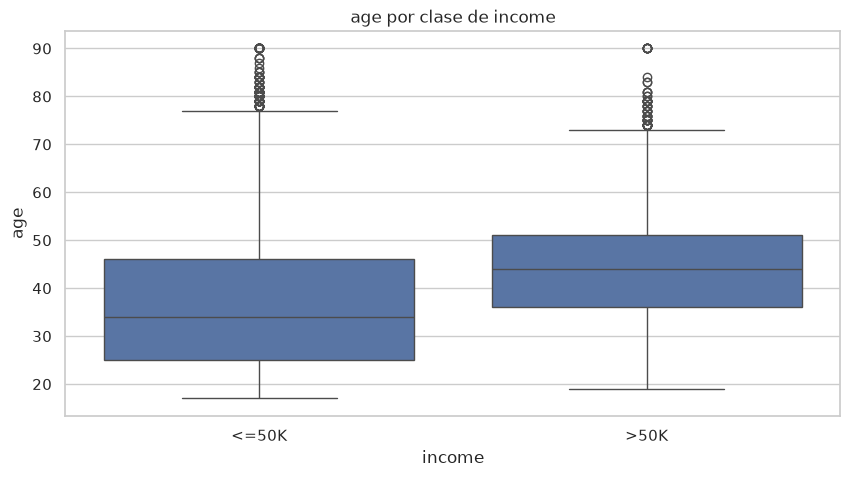

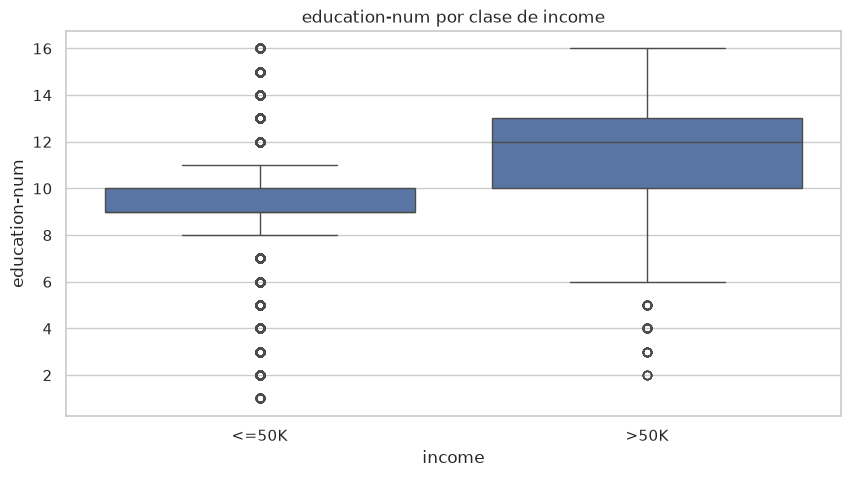

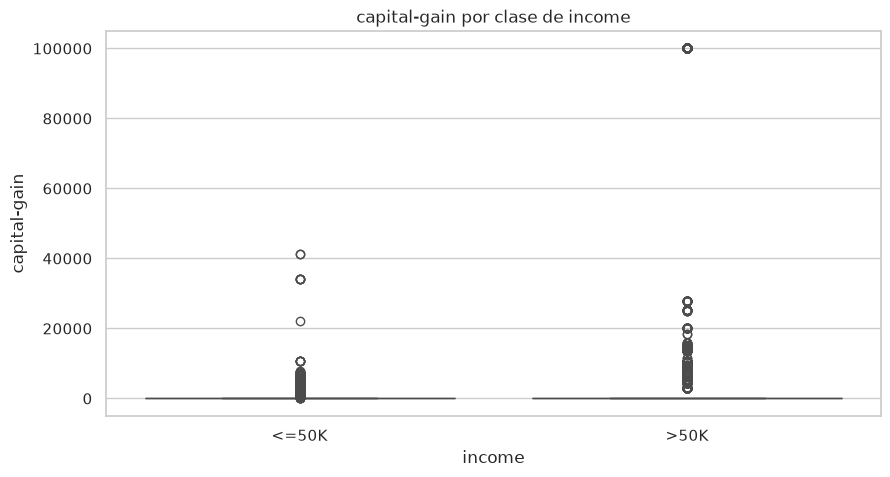

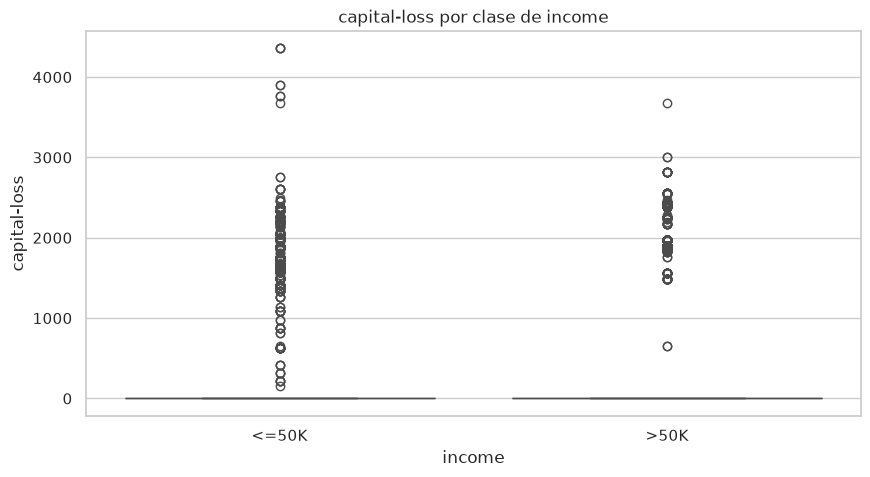

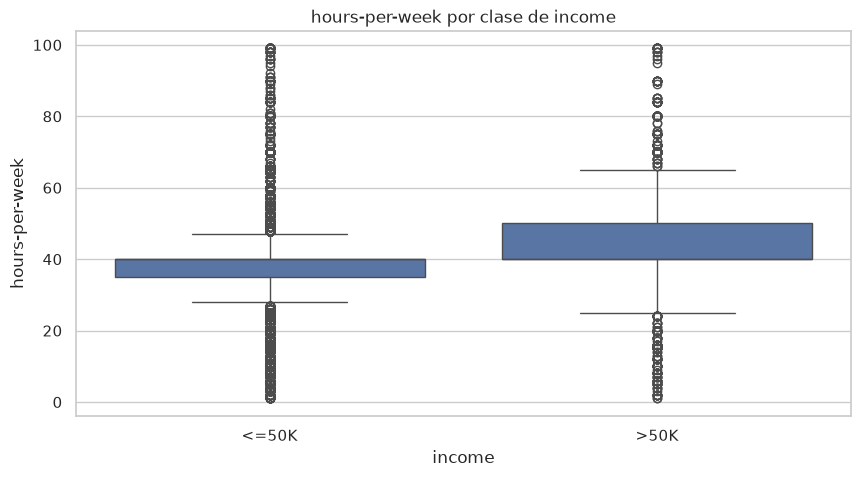

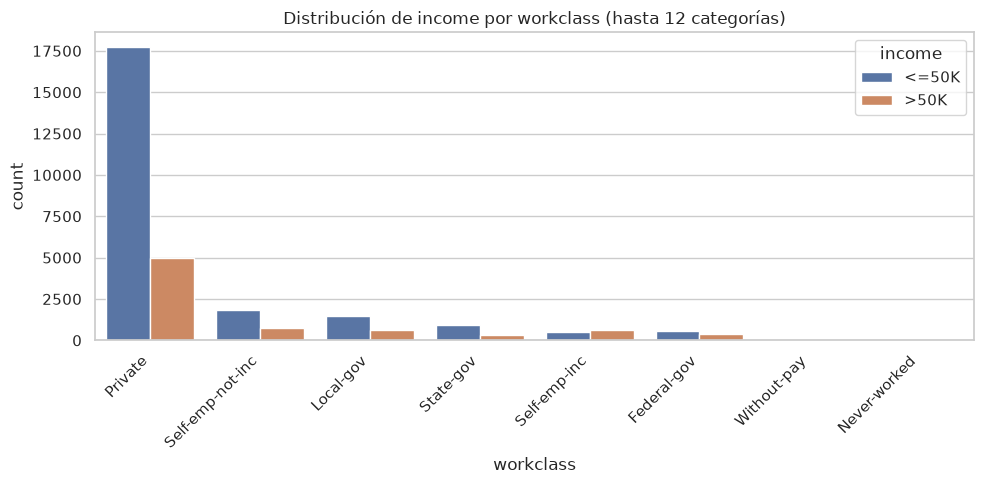

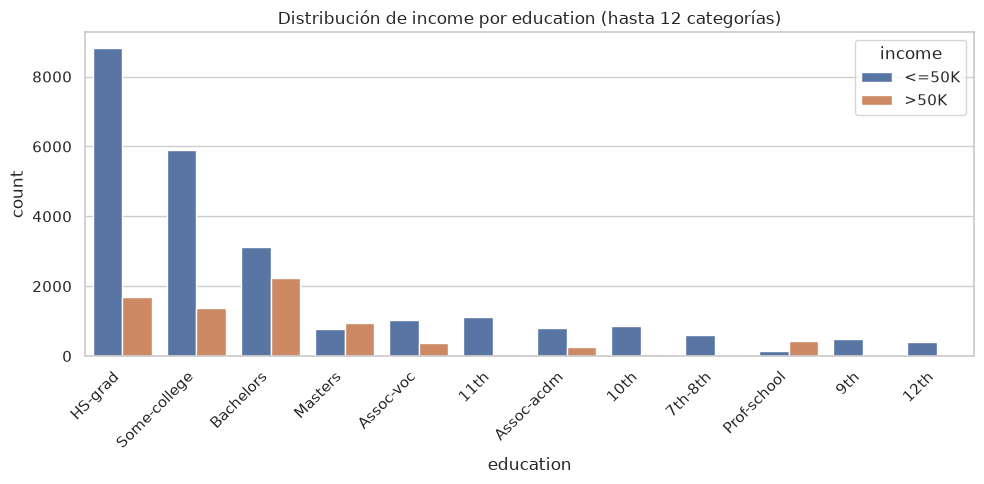

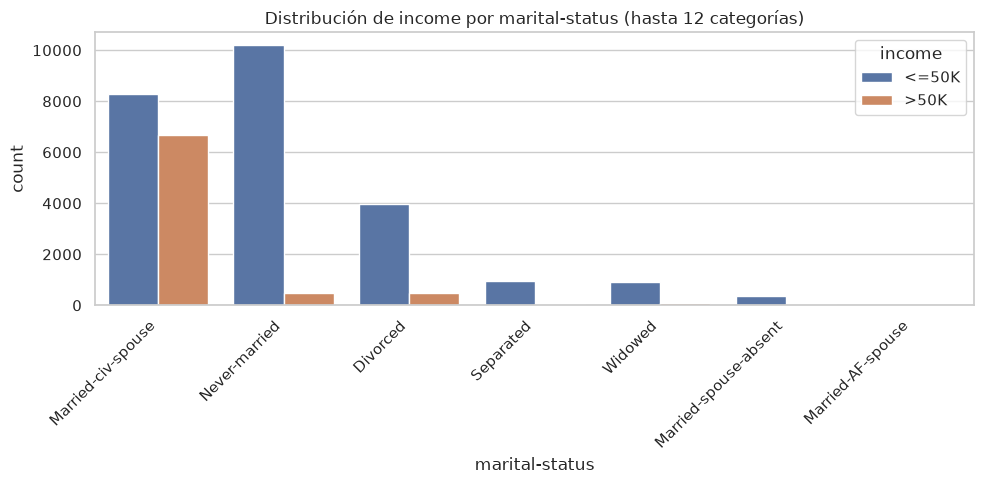

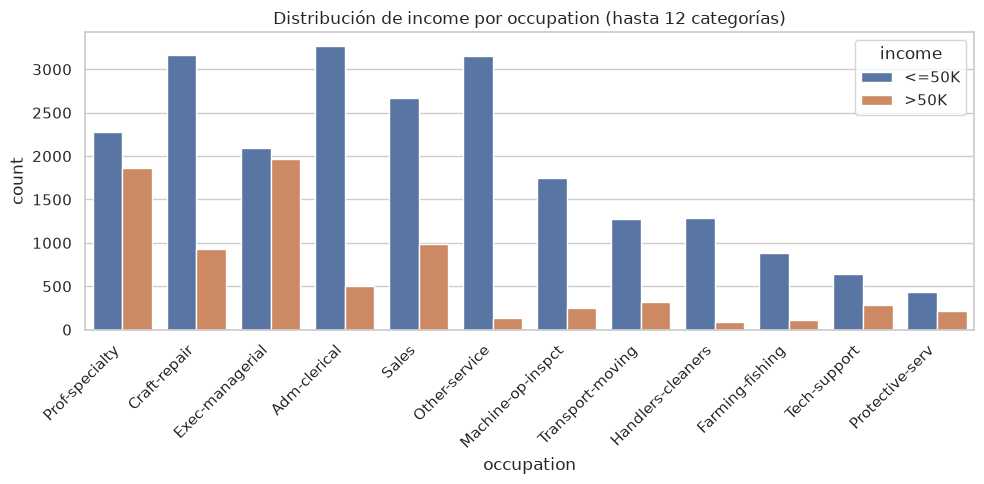

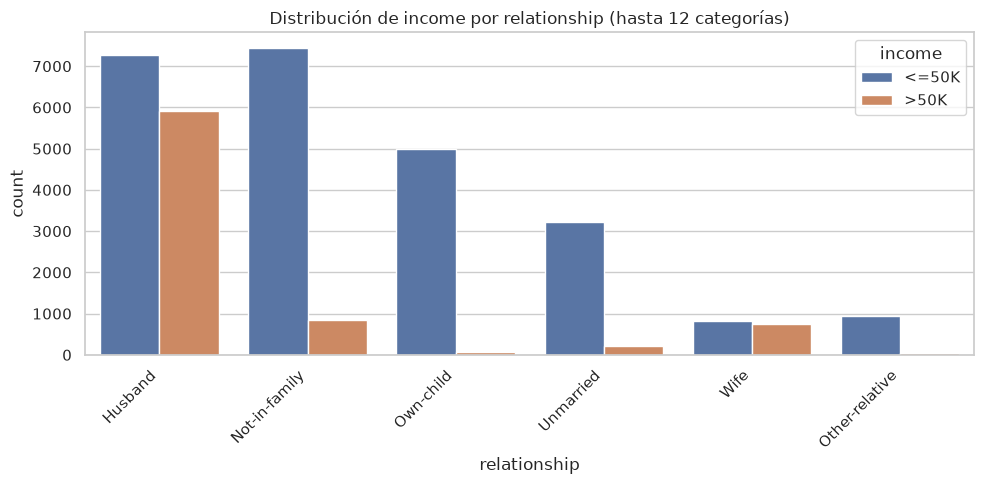

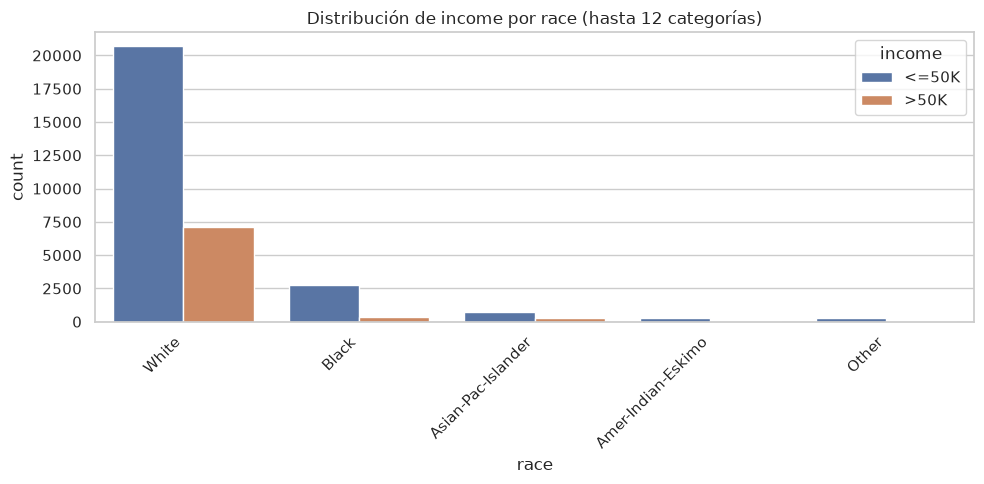

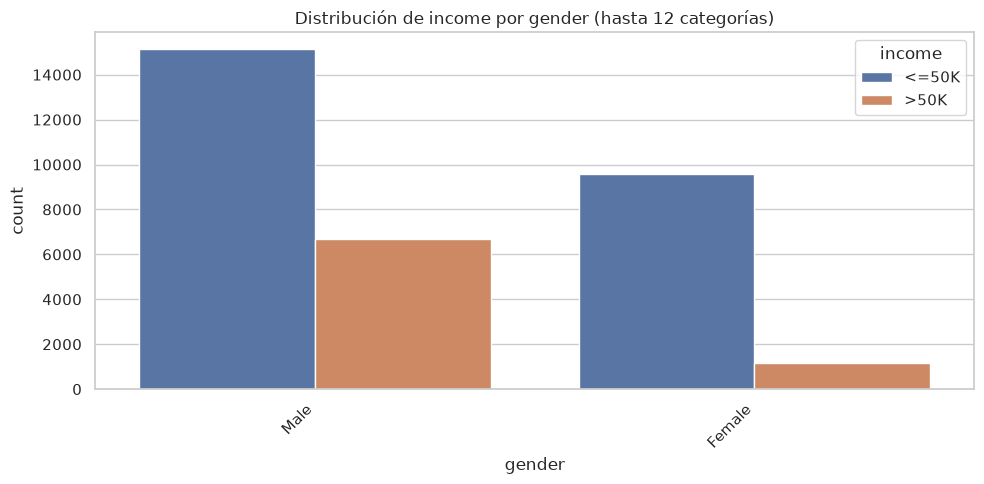

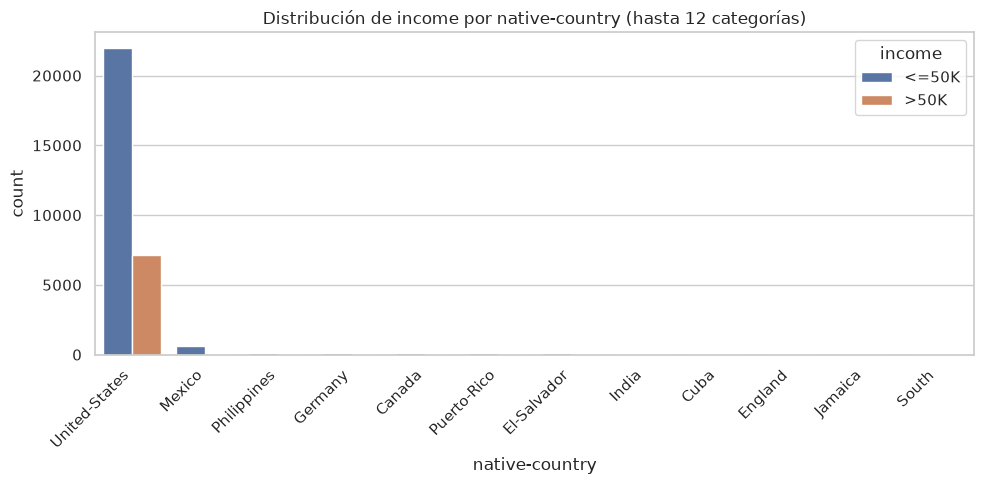

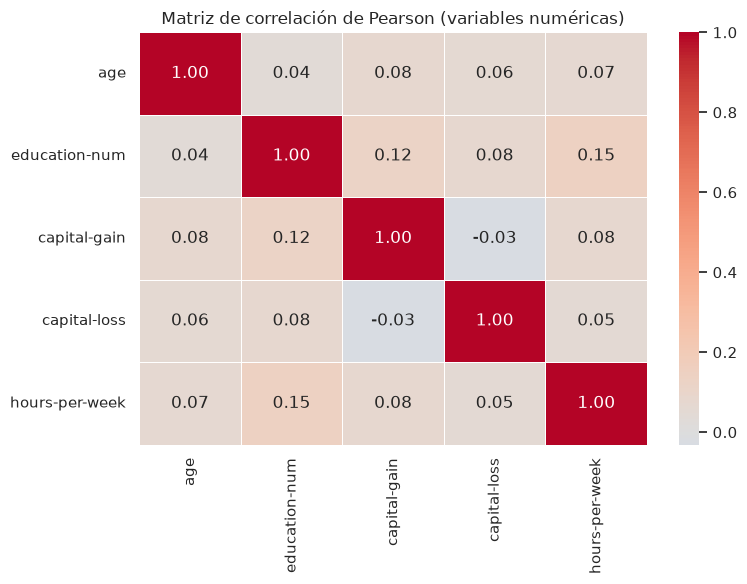

✓ Ningún par de variables numéricas supera |r| = 0.8.


,variable,VIF
0,age,1.01
1,education-num,1.04
2,capital-gain,1.03
3,capital-loss,1.01
4,hours-per-week,1.03


✓ VIF de todos los predictores ≤ 5.0: sin indicios de multicolinealidad.
         DIAGNÓSTICO COMPLETADO · 13 observaciones registradas          
Para la interpretación final ejecuta: eda.obtener_hallazgos()


,punto,tipo,detalle
0,4,duplicados,3466 filas duplicadas detectadas: evaluar si s...
1,5,nulos,'workclass': 1836 nulos (5.64%) → severidad me...
2,5,nulos,'occupation': 1843 nulos (5.66%) → severidad m...
3,5,nulos,'capital-gain': 1 nulos (0.00%) → severidad ba...
4,5,nulos,'capital-loss': 1 nulos (0.00%) → severidad ba...
5,5,nulos,'native-country': 583 nulos (1.79%) → severida...
6,6,outliers,'age': 143 valores atípicos (0.44%) y 0 extrem...
7,6,outliers,'education-num': 1198 valores atípicos (3.68%)...
8,6,outliers,'capital-gain': 2713 valores atípicos (8.33%) ...
9,6,outliers,'capital-loss': 1519 valores atípicos (4.66%) ...


In [4]:
# Busca la carpeta del módulo de la Actividad 1 tanto desde la carpeta actual como desde su carpeta padre.
rutas_eda = [Path.cwd() / "Ac_In_Apli_ML", Path.cwd().parent / "Ac_In_Apli_ML", Path.cwd().parent.parent / "Ac_In_Apli_ML"]
# Selecciona la primera carpeta que contenga el archivo reutilizable de EDA.
ruta_eda = next((ruta for ruta in rutas_eda if (ruta / "herramientas_eda.py").is_file()), None)
# Detiene la ejecución con una instrucción concreta si se abrió el notebook fuera del repositorio y no se descargó el módulo.
if ruta_eda is None:
    raise FileNotFoundError("No se encontró Ac_In_Apli_ML/herramientas_eda.py; ejecuta el notebook desde el repositorio completo.")
# Agrega al import path la carpeta que contiene el módulo de la Actividad 1.
sys.path.insert(0, str(ruta_eda))
# Importa la clase original para reutilizarla sin duplicar ni alterar su implementación.
from herramientas_eda import AutoEDA
# Crea el diagnóstico automatizado indicando el target categórico del problema.
eda = AutoEDA(df, target_col=TARGET, figsize=(10, 5))
# Ejecuta los pasos de EDA automatizado sobre el dataset completo.
eda.run_analysis()
# Recupera y muestra las observaciones que deben discutirse en el reporte.
hallazgos_eda = eda.obtener_hallazgos()
hallazgos_eda

### Interpretación del EDA

Revisa el reporte y los gráficos generados antes de modelar. En Adult, `?` representa faltantes; la limpieza anterior los traduce a valores faltantes para que el EDA los detecte. La proporción de `>50K` debe compararse con la de `<=50K`: una clase minoritaria puede tener recall bajo aunque la accuracy parezca alta. Los atípicos identificados no se eliminan automáticamente. Anota en el PDF qué hallazgos observas con los valores que se imprimieron en tu ejecución.

## Paso 4 — Partición y pipeline de preprocesamiento

Se reservan datos de prueba estratificados y se realizan búsquedas únicamente con los datos de entrenamiento. Para limitar el costo de cómputo, el modelado utiliza una muestra estratificada de hasta 8 000 filas. Los imputadores y el codificador son pasos del pipeline, por lo que se ajustan dentro de cada fold y no filtran información del conjunto de validación o prueba. Los atributos `race` y `gender/sex` se excluyen deliberadamente.

In [5]:
# Importa la función de partición estratificada para separar la muestra y los conjuntos de entrenamiento y prueba.
from sklearn.model_selection import train_test_split
# Define las columnas protegidas presentes en la versión local o descargada del dataset.
columnas_protegidas = [col for col in ["race", "gender", "sex"] if col in df.columns]
# Informa explícitamente qué atributos se excluirán del modelo.
print("Atributos protegidos excluidos:", columnas_protegidas)
# Selecciona una muestra aleatoria estratificada, o usa todo el dataset si tiene 8 000 filas o menos.
if len(df) > 8000:
    # Mantiene las proporciones de ingreso en la muestra que se usará para comparar hiperparámetros.
    datos_modelado, _ = train_test_split(df, train_size=8000, random_state=SEMILLA, stratify=df[TARGET])
else:
    # Evita reducir el dataset cuando ya es pequeño.
    datos_modelado = df.copy()
# Separa predictores del target y excluye columnas identificadoras o protegidas.
X = datos_modelado.drop(columns=[TARGET] + columnas_protegidas)
# Codifica la clase positiva como 1 y la clase <=50K como 0 para las métricas binarias.
y = datos_modelado[TARGET].map({"<=50K": 0, ">50K": 1}).astype("int8")
# Crea conjuntos de entrenamiento y prueba conservando la proporción de ambas clases.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEMILLA, stratify=y)
# Obtiene columnas numéricas por tipo de dato sin calcular estadísticas a partir de la prueba.
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()
# Obtiene columnas categóricas para imputarlas y codificarlas dentro del pipeline.
columnas_categoricas = X_train.select_dtypes(exclude=np.number).columns.tolist()
# Resume los tamaños y proporciones de clase de cada partición.
print(f"Muestra={len(datos_modelado)} | train={len(X_train)} | test={len(X_test)}")
print("Proporción positiva train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print(f"Predictores numéricos={len(columnas_numericas)} | categóricos={len(columnas_categoricas)}")

Atributos protegidos excluidos: ['race', 'gender']
Muestra=8000 | train=6000 | test=2000
Proporción positiva train/test: 0.241 0.241
Predictores numéricos=5 | categóricos=6


In [6]:
# Importa el constructor de transformaciones por tipo de columna.
from sklearn.compose import ColumnTransformer
# Importa los imputadores simples de valores faltantes.
from sklearn.impute import SimpleImputer
# Importa el codificador one-hot para convertir categorías en columnas numéricas.
from sklearn.preprocessing import OneHotEncoder
# Importa Pipeline para encadenar preprocesamiento y estimador sin fuga entre folds.
from sklearn.pipeline import Pipeline
# Construye el pipeline numérico: mediana calculada solo con los datos del fold de entrenamiento.
pipeline_numerico = Pipeline(steps=[("imputador", SimpleImputer(strategy="median"))])
# Construye el pipeline categórico: moda para faltantes y codificación robusta a categorías no vistas.
pipeline_categorico = Pipeline(steps=[("imputador", SimpleImputer(strategy="most_frequent")), ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
# Aplica a cada tipo de columna su transformación y descarta columnas que no pertenezcan al modelo.
preprocesador = ColumnTransformer(transformers=[("numericas", pipeline_numerico, columnas_numericas), ("categoricas", pipeline_categorico, columnas_categoricas)], remainder="drop", verbose_feature_names_out=True)
# Comprueba que todas las transformaciones están definidas antes de iniciar la búsqueda.
print(preprocesador)

ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='median'))]),
                                 ['age', 'education-num', 'capital-gain',
                                  'capital-loss', 'hours-per-week']),
                                ('categoricas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('one_hot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['workclass', 'education', 'marital-status',
                                  'occupation', 'relationship',
                                  'native-country'])])


## Paso 5 — Modelo, métrica de selección y búsquedas

Se utiliza un único modelo: `RandomForestClassifier`. La métrica de selección es el promedio simple entre **accuracy** y **recall de la clase positiva `>50K`**, ambas calculadas por validación cruzada estratificada. Esto impide elegir una configuración basándose solo en la clase mayoritaria y da el mismo peso a aciertos globales y detección de ingresos altos. Se comparan Grid Search, Randomized Search y BayesSearchCV con un espacio discreto compartido; el tiempo incluye el ajuste de cada búsqueda.

In [7]:
# Importa los tres buscadores y la estrategia de validación cruzada estratificada.
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold
# Importa RandomForestClassifier como el único algoritmo de clasificación de la práctica.
from sklearn.ensemble import RandomForestClassifier
# Importa constructores de puntuación y métricas para definir el criterio combinado.
from sklearn.metrics import accuracy_score, recall_score, make_scorer
# Importa los espacios categóricos necesarios para la optimización bayesiana.
from skopt import BayesSearchCV
from skopt.space import Categorical
# Define la métrica combinada: accuracy y recall positivo aportan exactamente la mitad cada uno.
def accuracy_recall(y_real, y_predicho):
    # Calcula accuracy, proporción total de predicciones correctas.
    exactitud = accuracy_score(y_real, y_predicho)
    # Calcula recall de la clase 1, proporción de ingresos >50K correctamente detectados.
    sensibilidad = recall_score(y_real, y_predicho, pos_label=1, zero_division=0)
    # Devuelve el promedio no ponderado que se usará para seleccionar hiperparámetros.
    return (exactitud + sensibilidad) / 2
# Registra la métrica combinada junto a accuracy y recall por separado en cada fold.
scoring = {"accuracy": "accuracy", "recall": "recall", "accuracy_recall": make_scorer(accuracy_recall)}
# Define una validación de tres folds que mantiene la proporción de clases en cada partición.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
# Crea el clasificador reproducible; el pipeline se ocupa de la preparación de datos.
clasificador = RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)
# Combina preprocesamiento y clasificador para que cada fold aprenda sus propias transformaciones.
pipeline_modelo = Pipeline(steps=[("preprocesador", preprocesador), ("modelo", clasificador)])
# Define el espacio común: 2 valores para árboles, profundidad, hoja y ponderación de clases.
espacio_discreto = {"modelo__n_estimators": [80, 140], "modelo__max_depth": [12, 20], "modelo__min_samples_leaf": [1, 3], "modelo__class_weight": [None, "balanced_subsample"]}
# Imprime el número de combinaciones exhaustivas que evaluará la búsqueda de rejilla.
print(f"Combinaciones Grid Search: {np.prod([len(valores) for valores in espacio_discreto.values()])}")

Combinaciones Grid Search: 16


In [8]:
# Crea la lista en que se guardarán los buscadores, sus resultados y sus tiempos.
resultados_busqueda = []
# Configura Grid Search para evaluar todas las combinaciones discretas disponibles.
busqueda_grid = GridSearchCV(estimator=pipeline_modelo, param_grid=espacio_discreto, scoring=scoring, refit="accuracy_recall", cv=cv, n_jobs=1, return_train_score=False)
# Registra el instante anterior al ajuste completo de la rejilla.
tiempo_inicio = time.perf_counter()
# Ajusta Grid Search solo con el conjunto de entrenamiento.
busqueda_grid.fit(X_train, y_train)
# Calcula el tiempo total de búsqueda en segundos.
tiempo_grid = time.perf_counter() - tiempo_inicio
# Guarda el nombre, objeto ajustado y duración para comparar posteriormente.
resultados_busqueda.append(("Grid Search", busqueda_grid, tiempo_grid))
# Informa el score combinado de validación cruzada obtenido por la rejilla.
print(f"Grid Search — score CV combinado={busqueda_grid.best_score_:.4f} | tiempo={tiempo_grid:.1f} s")

Grid Search — score CV combinado=0.8172 | tiempo=12.6 s


In [9]:
# Usa exactamente las alternativas discretas de Grid Search, muestreadas sin enumerar todas.
busqueda_random = RandomizedSearchCV(estimator=pipeline_modelo, param_distributions=espacio_discreto, n_iter=12, scoring=scoring, refit="accuracy_recall", cv=cv, random_state=SEMILLA, n_jobs=1, return_train_score=False)
# Registra el instante anterior al ajuste aleatorio.
tiempo_inicio = time.perf_counter()
# Ajusta Randomized Search únicamente con los datos de entrenamiento.
busqueda_random.fit(X_train, y_train)
# Calcula el tiempo total de la búsqueda aleatoria en segundos.
tiempo_random = time.perf_counter() - tiempo_inicio
# Almacena el resultado para la comparación de los tres métodos.
resultados_busqueda.append(("Randomized Search", busqueda_random, tiempo_random))
# Informa el mejor promedio de accuracy y recall de la validación cruzada.
print(f"Randomized Search — score CV combinado={busqueda_random.best_score_:.4f} | tiempo={tiempo_random:.1f} s")

Randomized Search — score CV combinado=0.8166 | tiempo=11.7 s


In [10]:
# Define el espacio bayesiano equivalente a las opciones discretas comparadas por los otros métodos.
espacio_bayesiano = {"modelo__n_estimators": Categorical([80, 140]), "modelo__max_depth": Categorical([12, 20]), "modelo__min_samples_leaf": Categorical([1, 3]), "modelo__class_weight": Categorical([None, "balanced_subsample"])}
# Configura doce iteraciones bayesianas con la misma validación cruzada y métrica combinada.
busqueda_bayes = BayesSearchCV(estimator=pipeline_modelo, search_spaces=espacio_bayesiano, n_iter=12, scoring=scoring, refit="accuracy_recall", cv=cv, random_state=SEMILLA, n_jobs=1, return_train_score=False)
# Registra el inicio para comparar tiempos de manera directa.
tiempo_inicio = time.perf_counter()
# Ajusta BayesSearchCV solo sobre la partición de entrenamiento.
busqueda_bayes.fit(X_train, y_train)
# Calcula la duración de la búsqueda bayesiana en segundos.
tiempo_bayes = time.perf_counter() - tiempo_inicio
# Agrega la búsqueda y su duración a los resultados comparables.
resultados_busqueda.append(("Optimización bayesiana", busqueda_bayes, tiempo_bayes))
# Informa el score CV combinado logrado por la búsqueda bayesiana.
print(f"Optimización bayesiana — score CV combinado={busqueda_bayes.best_score_:.4f} | tiempo={tiempo_bayes:.1f} s")

Optimización bayesiana — score CV combinado=0.8172 | tiempo=12.9 s


## Paso 6 — Comparación de métodos y selección del mejor

La tabla compara los promedios de validación cruzada (no los resultados de test) y el tiempo de ajuste. Cada método se ejecuta en el mismo espacio de hiperparámetros, con el mismo pipeline, la misma métrica y los mismos folds. Se selecciona por el mayor promedio `accuracy_recall`; en caso de empate, prevalece la mayor recall para priorizar la clase positiva. El conjunto de prueba sigue reservado.

In [11]:
# Crea una fila de comparación por cada búsqueda ejecutada.
filas_resultados = []
# Recupera los mejores resultados CV y el tiempo total reportado para cada buscador.
for nombre, busqueda, duracion in resultados_busqueda:
    # Identifica la fila de cv_results_ correspondiente a los hiperparámetros ganadores.
    indice_mejor = busqueda.best_index_
    # Guarda score combinado, accuracy, recall, duración y los parámetros seleccionados.
    filas_resultados.append({"Método": nombre, "Accuracy CV": busqueda.cv_results_["mean_test_accuracy"][indice_mejor], "Recall CV (>50K)": busqueda.cv_results_["mean_test_recall"][indice_mejor], "Score combinado CV": busqueda.cv_results_["mean_test_accuracy_recall"][indice_mejor], "Tiempo (s)": duracion, "Mejores hiperparámetros": busqueda.best_params_})
# Ordena de mayor a menor por score combinado y luego por recall positiva.
tabla_comparacion = pd.DataFrame(filas_resultados).sort_values(["Score combinado CV", "Recall CV (>50K)"], ascending=False).reset_index(drop=True)
# Muestra los valores medidos para sustentar la justificación del método ganador.
display(tabla_comparacion)
# Selecciona la búsqueda ganadora solo con resultados de validación cruzada.
nombre_ganador = tabla_comparacion.loc[0, "Método"]
# Recupera el objeto de búsqueda asociado al nombre ganador.
busqueda_ganadora = next(busqueda for nombre, busqueda, _ in resultados_busqueda if nombre == nombre_ganador)
# Imprime el método elegido y su combinación de hiperparámetros.
print("Método seleccionado por CV:", nombre_ganador)
print("Hiperparámetros seleccionados:", busqueda_ganadora.best_params_)

,Método,Accuracy CV,Recall CV (>50K),Score combinado CV,Tiempo (s),Mejores hiperparámetros
0,Grid Search,0.799167,0.835299,0.817233,12.589416,"{'modelo__class_weight': 'balanced_subsample',..."
1,Optimización bayesiana,0.799167,0.835299,0.817233,12.895215,"{'modelo__class_weight': 'balanced_subsample',..."
2,Randomized Search,0.799333,0.833913,0.816623,11.659427,"{'modelo__n_estimators': 140, 'modelo__min_sam..."


Método seleccionado por CV: Grid Search
Hiperparámetros seleccionados: {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 80}


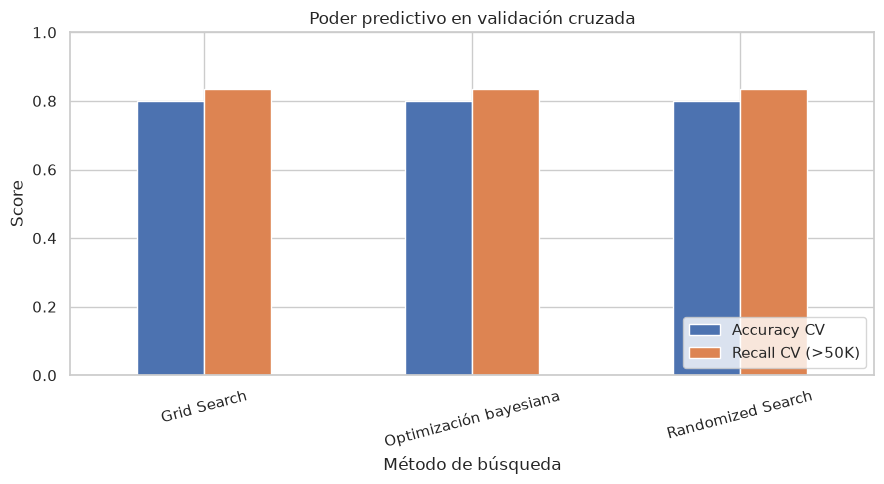

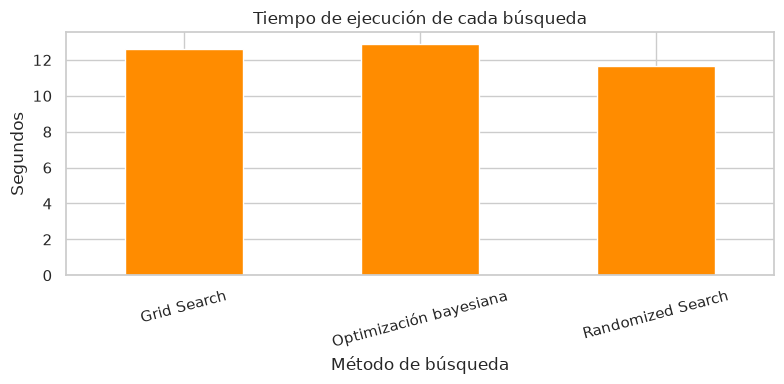

In [12]:
# Dibuja accuracy y recall de validación cruzada para comparar el poder predictivo de las búsquedas.
ax = tabla_comparacion.set_index("Método")[["Accuracy CV", "Recall CV (>50K)"]].plot(kind="bar", figsize=(9, 5), ylim=(0, 1), rot=15)
# Añade título y etiquetas que identifican las métricas y su escala.
ax.set(title="Poder predictivo en validación cruzada", ylabel="Score", xlabel="Método de búsqueda")
# Coloca la leyenda fuera del área de las barras para facilitar su lectura.
ax.legend(loc="lower right")
# Ajusta márgenes para evitar recortes del texto.
plt.tight_layout()
# Renderiza la figura comparativa.
plt.show()
# Compara los tiempos medidos de las tres búsquedas.
ax = tabla_comparacion.set_index("Método")["Tiempo (s)"].plot(kind="bar", figsize=(8, 4), color="darkorange", rot=15)
# Describe la unidad temporal del gráfico.
ax.set(title="Tiempo de ejecución de cada búsqueda", ylabel="Segundos", xlabel="Método de búsqueda")
# Ajusta la figura para que las etiquetas sean visibles.
plt.tight_layout()
# Muestra los tiempos comparados.
plt.show()

### Cómo redactar la comparación

Usa los valores de la tabla y los gráficos de tu ejecución: indica cuál obtuvo mejor `Score combinado CV`, cuál detectó más casos `>50K` (recall) y cuál demoró menos. Si dos métodos quedan cerca, explica que una sola muestra y un número limitado de evaluaciones no prueban que uno sea universalmente superior. El score CV es la base para la selección; no se escoge el modelo por su resultado de test.

## Paso 7 — Entrenamiento final y evaluación en test

Se crea y ajusta una instancia nueva del pipeline con los hiperparámetros del ganador, usando todos los datos de entrenamiento. El conjunto de prueba se consulta una sola vez para estimar la generalización. La matriz de confusión se presenta como TN, FP, FN y TP; ROC y AUC resumen el comportamiento a distintos umbrales, mientras que la decisión actual usa umbral 0.5.

In [13]:
# Importa clone para construir un pipeline nuevo sin reutilizar objetos ya ajustados durante CV.
from sklearn.base import clone
# Importa métricas de clasificación, matriz de confusión y curva ROC.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
# Clona el pipeline base y asigna los mejores hiperparámetros elegidos exclusivamente con CV.
modelo_final = clone(pipeline_modelo).set_params(**busqueda_ganadora.best_params_)
# Ajusta el modelo final con todas las filas de entrenamiento disponibles.
modelo_final.fit(X_train, y_train)
# Predice la clase de los ejemplos que no participaron en el ajuste ni en la búsqueda.
y_pred = modelo_final.predict(X_test)
# Obtiene la probabilidad de clase positiva para cada ejemplo del conjunto de prueba.
y_prob = modelo_final.predict_proba(X_test)[:, list(modelo_final.classes_).index(1)]
# Imprime accuracy y recall positiva con valores definidos explícitamente.
print(f"Accuracy test: {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall test (>50K): {recall_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
# Calcula y reporta AUC usando las probabilidades positivas.
print(f"ROC-AUC test: {roc_auc_score(y_test, y_prob):.4f}")
# Resume precision, recall y F1 para cada clase con nombres comprensibles.
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["<=50K", ">50K"], zero_division=0))

Accuracy test: 0.8090
Recall test (>50K): 0.8361
ROC-AUC test: 0.9050
              precision    recall  f1-score   support

       <=50K       0.94      0.80      0.86      1518
        >50K       0.57      0.84      0.68       482

    accuracy                           0.81      2000
   macro avg       0.75      0.82      0.77      2000
weighted avg       0.85      0.81      0.82      2000



TN=1215 | FP=303 | FN=79 | TP=403


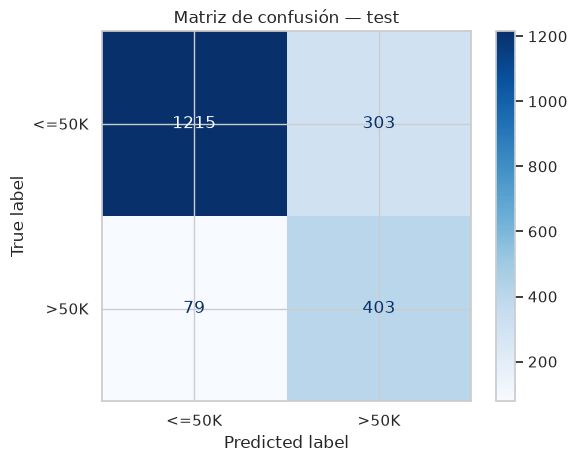

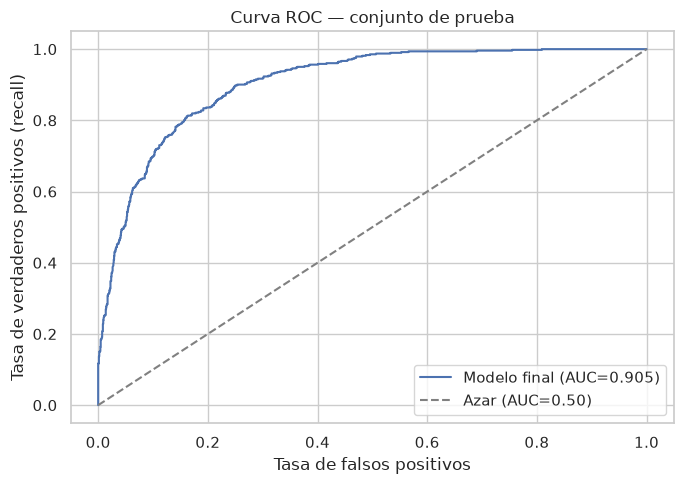

In [14]:
# Calcula la matriz de confusión en el orden fijo: clase real/predicha 0 y luego 1.
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1])
# Muestra cada conteo como TN, FP, FN y TP en el orden de filas y columnas.
print(f"TN={matriz[0, 0]} | FP={matriz[0, 1]} | FN={matriz[1, 0]} | TP={matriz[1, 1]}")
# Construye un gráfico legible con los nombres de las etiquetas.
ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=["<=50K", ">50K"]).plot(cmap="Blues", values_format="d")
# Añade un título que indica que la matriz corresponde al conjunto de prueba.
plt.title("Matriz de confusión — test")
# Muestra los falsos positivos y negativos para su interpretación.
plt.show()
# Calcula la tasa de falsos positivos, la tasa de verdaderos positivos y los umbrales ROC.
fpr, tpr, umbrales_roc = roc_curve(y_test, y_prob, pos_label=1)
# Calcula el área bajo la curva ROC de la probabilidad de ingresos >50K.
auc_test = roc_auc_score(y_test, y_prob)
# Dibuja la curva ROC sobre la diagonal que representa clasificación aleatoria.
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Modelo final (AUC={auc_test:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC=0.50)")
# Etiqueta los ejes con sus tasas para interpretar sensibilidad y falsos positivos.
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
# Añade título y leyenda a la curva.
plt.title("Curva ROC — conjunto de prueba")
plt.legend(loc="lower right")
# Ajusta y muestra la gráfica.
plt.tight_layout()
plt.show()

### Interpretación de evaluación

En la matriz, **FN** son personas `>50K` que el modelo no detectó y **FP** son personas `<=50K` clasificadas como `>50K`. La curva ROC muestra el intercambio entre detección positiva y falsas alarmas cuando cambia el umbral; un AUC cercano a 1 discrimina mejor que 0.5. Discute accuracy junto a recall y considera el costo de ambos tipos de error; ninguna de estas métricas, por sí sola, valida el uso social del modelo.

## Paso 8 — IA explicativa global: importancia nativa

La importancia nativa de Random Forest resume cuánto disminuyen las impurezas de los árboles al usar cada variable codificada. Las categorías codificadas en varias columnas aparecen desglosadas. Esta medida puede favorecer variables categóricas con muchos niveles y no debe interpretarse como causalidad.

,Importancia nativa
categoricas__marital-status_Married-civ-spouse,0.199258
numericas__education-num,0.102107
numericas__age,0.098742
categoricas__relationship_Husband,0.089963
numericas__capital-gain,0.080469
numericas__hours-per-week,0.068341
categoricas__marital-status_Never-married,0.059807
categoricas__occupation_Exec-managerial,0.028379
categoricas__relationship_Own-child,0.023062
categoricas__relationship_Not-in-family,0.021624


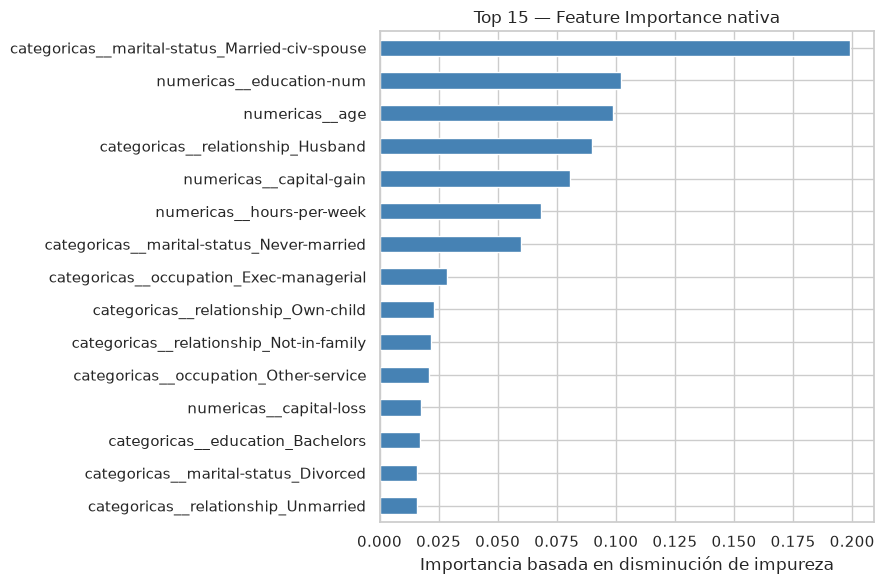

In [15]:
# Obtiene el estimador Random Forest ya entrenado dentro del pipeline final.
modelo_rf = modelo_final.named_steps["modelo"]
# Obtiene los nombres de las columnas después de imputación y One-Hot Encoding.
nombres_features = modelo_final.named_steps["preprocesador"].get_feature_names_out()
# Alinea importancia nativa y nombres de las variables transformadas.
importancia_nativa = pd.Series(modelo_rf.feature_importances_, index=nombres_features, name="Importancia nativa").sort_values(ascending=False)
# Muestra las quince variables codificadas con mayor importancia interna.
display(importancia_nativa.head(15).to_frame())
# Grafica el ranking superior para facilitar la interpretación global.
importancia_nativa.head(15).sort_values().plot(kind="barh", figsize=(9, 6), color="steelblue")
# Etiqueta el eje de importancia y el título del gráfico.
plt.xlabel("Importancia basada en disminución de impureza")
plt.title("Top 15 — Feature Importance nativa")
# Ajusta y muestra la figura.
plt.tight_layout()
plt.show()

## Paso 9 — IA explicativa global: Permutation Importance

Se permuta cada variable original del conjunto de prueba y se mide cuánto cae la misma métrica combinada usada en la búsqueda. Aquí las variables categóricas no se dividen en columnas one-hot, por lo que el ranking es más fácil de leer como atributo original. Una caída pequeña o negativa significa que, con esta muestra, permutar la variable no empeoró el score; no prueba que sea irrelevante en cualquier población.

,Importancia media,Desviación estándar
marital-status,0.135178,0.005731
relationship,0.060674,0.005704
capital-gain,0.027956,0.001406
age,0.026542,0.003718
occupation,0.019069,0.004467
hours-per-week,0.014257,0.002512
education-num,0.006738,0.002317
education,0.001626,0.003681
native-country,0.001550,0.000832
capital-loss,0.001121,0.001261


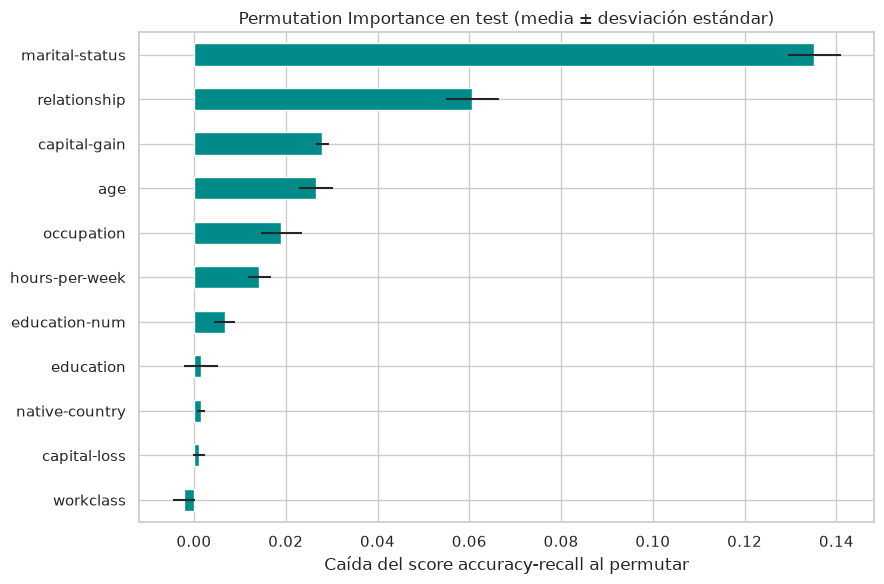

In [16]:
# Importa la utilidad de permutación de scikit-learn.
from sklearn.inspection import permutation_importance
# Permuta cada predictor original en test y mide la caída del score combinado en tres repeticiones.
resultado_permutacion = permutation_importance(modelo_final, X_test, y_test, scoring=make_scorer(accuracy_recall), n_repeats=3, random_state=SEMILLA, n_jobs=1)
# Resume promedio y desviación estándar de la caída de score por predictor.
importancia_permutacion = pd.DataFrame({"Importancia media": resultado_permutacion.importances_mean, "Desviación estándar": resultado_permutacion.importances_std}, index=X_test.columns).sort_values("Importancia media", ascending=False)
# Muestra las quince variables originales más influyentes en esta medición.
display(importancia_permutacion.head(15))
# Grafica las importancias promedio en orden ascendente para que el mayor valor quede arriba.
importancia_permutacion.head(15).sort_values("Importancia media").plot.barh(y="Importancia media", xerr="Desviación estándar", figsize=(9, 6), color="darkcyan", legend=False)
# Etiqueta la caída del score combinado y el título de la gráfica.
plt.xlabel("Caída del score accuracy-recall al permutar")
plt.title("Permutation Importance en test (media ± desviación estándar)")
# Ajusta y muestra el gráfico.
plt.tight_layout()
plt.show()

## Paso 10 — IA explicativa global: valores SHAP

SHAP distribuye la diferencia entre la predicción y una predicción base entre las variables del modelo. El árbol se explica sobre los datos ya transformados por el mismo preprocesador. Para los gráficos se explica la clase positiva `>50K`; valores positivos elevan su salida respecto de la base y valores negativos la reducen. Se limita la explicación a 200 registros aleatorios del test para mantener un tiempo razonable.

/tmp/integradora3-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


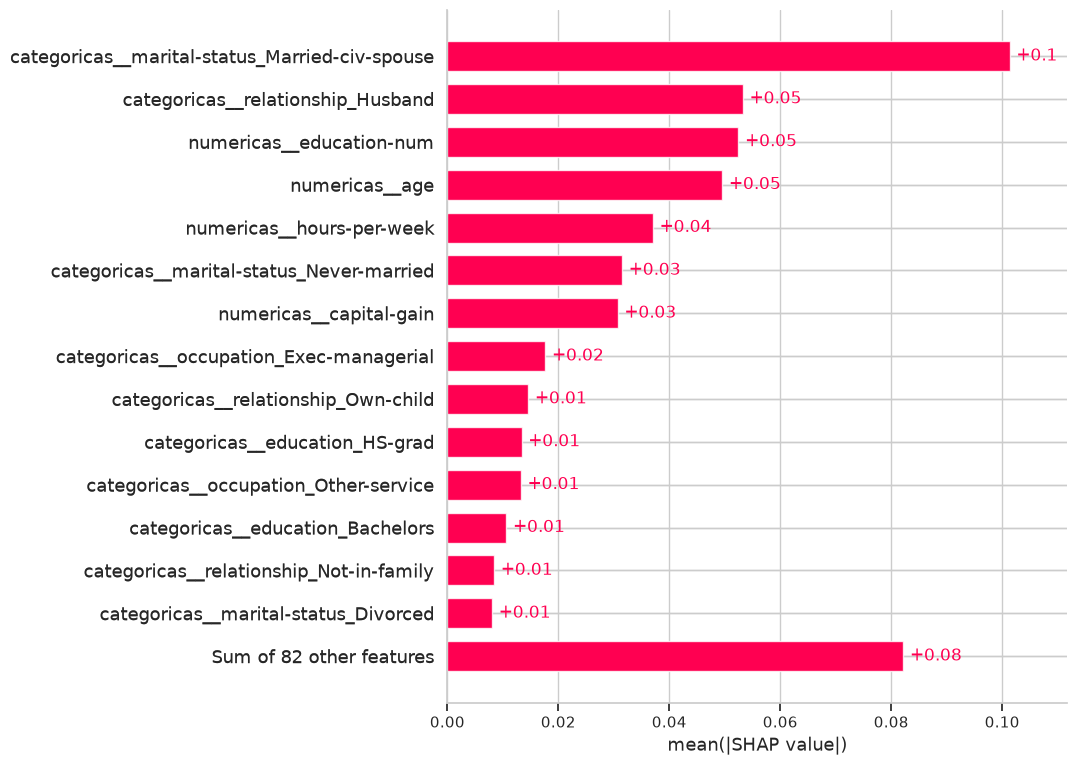

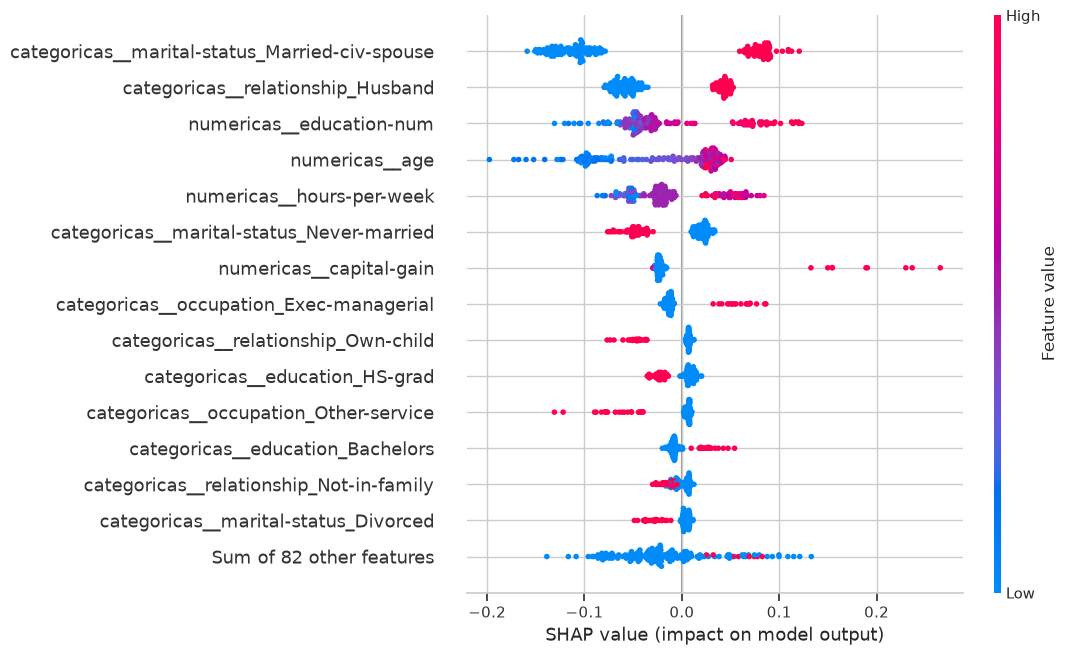

In [17]:
# Importa SHAP para calcular explicaciones compatibles con árboles de decisión.
import shap
# Transforma solamente una muestra del test con el preprocesador ya ajustado del modelo final.
X_test_transformado = modelo_final.named_steps["preprocesador"].transform(X_test)
# Convierte la matriz a DataFrame y conserva los nombres de las columnas transformadas.
X_test_transformado = pd.DataFrame(X_test_transformado, columns=nombres_features, index=X_test.index)
# Selecciona hasta 200 observaciones de test de forma reproducible para explicar.
X_shap = X_test_transformado.sample(n=min(200, len(X_test_transformado)), random_state=SEMILLA)
# Crea el explicador nativo del Random Forest final.
explainer = shap.TreeExplainer(modelo_rf)
# Calcula valores SHAP para cada observación de la muestra explicable.
explicacion_shap = explainer(X_shap)
# Selecciona las contribuciones de la clase positiva si SHAP devuelve también el eje de clases.
if explicacion_shap.values.ndim == 3:
    # En la clasificación binaria se toma el índice 1, correspondiente a ingresos >50K.
    explicacion_positiva = explicacion_shap[:, :, 1]
else:
    # Mantiene la explicación directamente cuando el objeto ya contiene una sola salida.
    explicacion_positiva = explicacion_shap
# Muestra el ranking global promedio de valores SHAP absolutos.
shap.plots.bar(explicacion_positiva, max_display=15)
# Muestra la dirección e intensidad de los valores SHAP para las variables más relevantes.
shap.plots.beeswarm(explicacion_positiva, max_display=15)

### Contrastar las tres importancias

Compara si las variables principales se repiten en Feature Importance nativa, Permutation Importance y SHAP. Las técnicas no miden exactamente lo mismo: impureza es interna al bosque, permutación mide caída de rendimiento en test y SHAP atribuye contribuciones a predicciones respecto de una base. Diferencias pueden deberse a variables correlacionadas, codificación one-hot, variabilidad muestral o a la medida elegida; no son explicaciones causales.

## Paso 11 — Predicción nueva y explicación SHAP local

Se toma una observación reservada del conjunto de prueba, que no participó en el ajuste final, como un caso nuevo para el modelo. Se presenta la probabilidad predicha, el resultado real para poder contextualizarlo y el waterfall SHAP de la clase `>50K`. Los valores de SHAP explican esta predicción concreta; no son una regla general para todas las personas.

Etiqueta real: >50K
Predicción del modelo: >50K
Probabilidad estimada de >50K: 0.670


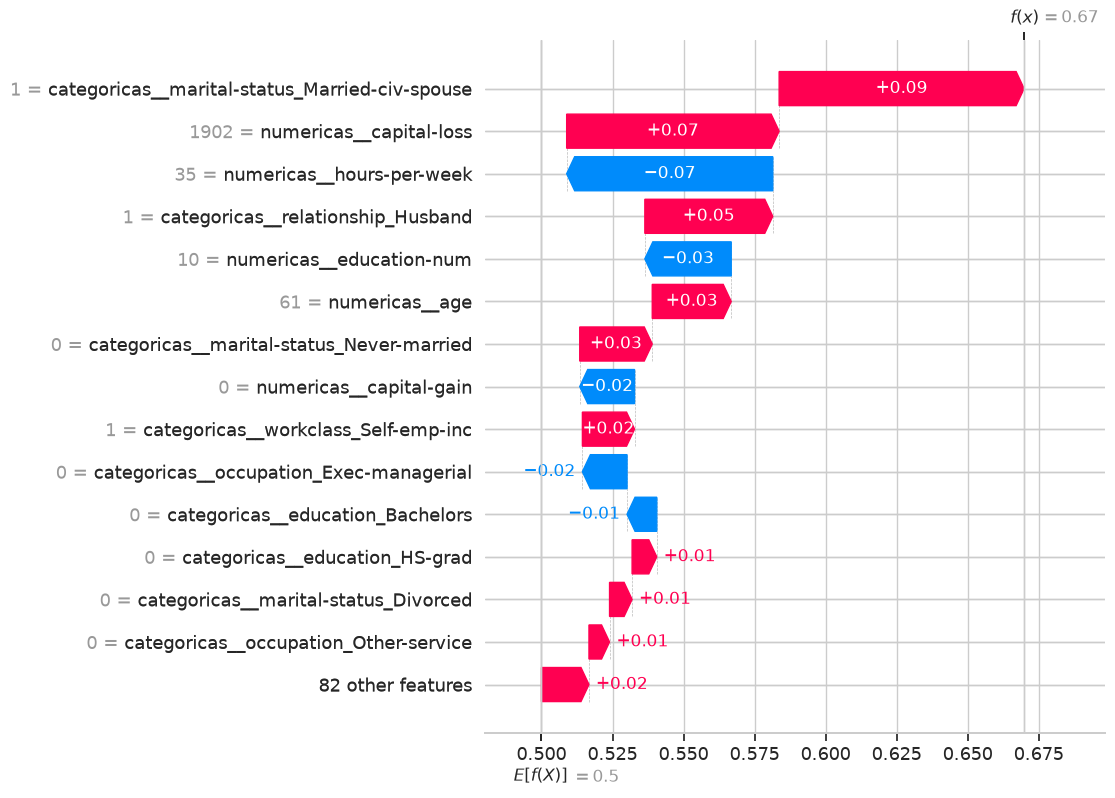

,Valor de la observación
age,61
workclass,Self-emp-inc
education,Some-college
education-num,10
marital-status,Married-civ-spouse
occupation,Sales
relationship,Husband
capital-gain,0.0
capital-loss,1902.0
hours-per-week,35


In [18]:
# Selecciona una fila de test como observación nueva y conserva su forma de DataFrame.
X_nuevo = X_test.iloc[[0]].copy()
# Recupera su etiqueta real solo para comparar la predicción durante la evaluación.
y_real_nuevo = int(y_test.iloc[0])
# Calcula la clase predicha y la probabilidad de ingresos >50K para esa fila.
prediccion_nueva = int(modelo_final.predict(X_nuevo)[0])
probabilidad_nueva = float(modelo_final.predict_proba(X_nuevo)[0, list(modelo_final.classes_).index(1)])
# Imprime la salida del modelo junto a la etiqueta real de la observación reservada.
print("Etiqueta real:", ">50K" if y_real_nuevo == 1 else "<=50K")
print("Predicción del modelo:", ">50K" if prediccion_nueva == 1 else "<=50K")
print(f"Probabilidad estimada de >50K: {probabilidad_nueva:.3f}")
# Transforma el caso con el preprocesador que se ajustó exclusivamente en entrenamiento.
X_nuevo_transformado = pd.DataFrame(modelo_final.named_steps["preprocesador"].transform(X_nuevo), columns=nombres_features)
# Calcula valores SHAP locales para el único caso nuevo.
explicacion_local = explainer(X_nuevo_transformado)
# Elige las contribuciones de la clase positiva para el gráfico waterfall.
if explicacion_local.values.ndim == 3:
    # Extrae la salida de clase 1 (>50K) del tensor SHAP multiclase.
    explicacion_local_positiva = explicacion_local[:, :, 1]
else:
    # Usa la explicación directamente si SHAP devuelve una única salida.
    explicacion_local_positiva = explicacion_local
# Grafica las contribuciones que elevan o reducen la predicción positiva de esta observación.
shap.plots.waterfall(explicacion_local_positiva[0], max_display=15)
# Muestra los valores originales del caso explicable sin incluir atributos protegidos.
display(X_nuevo.T.rename(columns={X_nuevo.index[0]: "Valor de la observación"}))

### Lectura de la explicación local

En el waterfall, `E[f(X)]` es la salida base y las contribuciones SHAP desplazan esa salida hacia el resultado del caso observado. Identifica las variables que más empujaron hacia `>50K` y las que más alejaron la predicción de esa clase. La salida del modelo se explica para la clase positiva; no debe interpretarse como causalidad ni como una justificación suficiente para decisiones de empleo, crédito u otros derechos.

## Paso 12 — Conclusiones y lista de cumplimiento

Completa el reporte PDF solicitado con el código, las salidas de tu ejecución y la interpretación basada en números reales. No copies valores de una ejecución ajena; la muestra estratificada y las versiones de librerías pueden cambiar resultados y tiempos.

- [ ] Dataset de clasificación diferente de Iris/Titanic, origen y variable objetivo identificados.
- [ ] Clase EDA de la Actividad 1 importada y ejecutada; hallazgos comentados.
- [ ] Limpieza inicial, faltantes, partición estratificada y pipeline sin fuga de datos explicados.
- [ ] Un modelo evaluado con Grid Search, Randomized Search y optimización bayesiana.
- [ ] Métrica que combina accuracy y recall positiva justificada; score CV y tiempos comparados.
- [ ] Modelo nuevo entrenado con hiperparámetros seleccionados y evaluación final en test.
- [ ] Matriz de confusión, curva ROC/AUC y tipos de error interpretados.
- [ ] Feature Importance, Permutation Importance y SHAP global contrastados.
- [ ] Predicción de una observación reservada explicada con SHAP local.
- [ ] Código comentado y explicación de las salidas incorporados al reporte PDF.
- [ ] Sesgos y límites de uso del dataset discutidos.

**Fuente:** Adult Census Income, repositorio del curso (`Unidad 1/adult.csv`) o OpenML Adult, versión 2. El modelo y las métricas son un ejercicio académico, no una herramienta para decisiones de alto impacto.